# 🐶 PawCare Dog Prediction

## Dog vs Non-Dog Detection + Dog Breed Classification

This notebook is used to test the trained PawCare Dog AI models without running the prediction script from the terminal.

### Pipeline

Dog Image
↓
Dog vs Non-Dog Detector
↓
If Dog → Dog Breed Classifier
↓
Top 3 Dog Breed Predictions

If Non-Dog → Reject Image

In [1]:
import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from PIL import Image
import tkinter as tk
from tkinter import filedialog

print("TensorFlow version:", tf.__version__)
print("Libraries loaded successfully!")

TensorFlow version: 2.21.0
Libraries loaded successfully!


In [2]:
# ============================================================
# PAWCARE DOG AI PATHS
# ============================================================

# Current notebook:
# PawCare/
# └── dog_breed/
#     └── notebooks/
#         └── dog_prediction.ipynb

# Go up:
# notebooks → dog_breed → PawCare

PROJECT_ROOT = os.path.abspath(
    os.path.join(
        os.getcwd(),
        "..",
        ".."
    )
)

print("Project Root:")
print(PROJECT_ROOT)


# ============================================================
# DOG DETECTOR
# ============================================================

DETECTOR_MODEL_PATH = os.path.join(
    PROJECT_ROOT,
    "dog_breed",
    "dog_detector",
    "models",
    "dog_detector.keras"
)

DETECTOR_CLASSES_PATH = os.path.join(
    PROJECT_ROOT,
    "dog_breed",
    "dog_detector",
    "models",
    "dog_detector_class_names.json"
)


# ============================================================
# DOG BREED CLASSIFIER
# ============================================================

BREED_MODEL_PATH = os.path.join(
    PROJECT_ROOT,
    "dog_breed",
    "models",
    "dog_breed_classifier.keras"
)

BREED_CLASSES_PATH = os.path.join(
    PROJECT_ROOT,
    "dog_breed",
    "models",
    "dog_class_names.json"
)


print("\nDog Detector Model:")
print(DETECTOR_MODEL_PATH)

print("\nDog Detector Classes:")
print(DETECTOR_CLASSES_PATH)

print("\nDog Breed Model:")
print(BREED_MODEL_PATH)

print("\nDog Breed Classes:")
print(BREED_CLASSES_PATH)

Project Root:
c:\Users\saisa\OneDrive\Documents\PawCare

Dog Detector Model:
c:\Users\saisa\OneDrive\Documents\PawCare\dog_breed\dog_detector\models\dog_detector.keras

Dog Detector Classes:
c:\Users\saisa\OneDrive\Documents\PawCare\dog_breed\dog_detector\models\dog_detector_class_names.json

Dog Breed Model:
c:\Users\saisa\OneDrive\Documents\PawCare\dog_breed\models\dog_breed_classifier.keras

Dog Breed Classes:
c:\Users\saisa\OneDrive\Documents\PawCare\dog_breed\models\dog_class_names.json


In [3]:
# ============================================================
# CHECK REQUIRED FILES
# ============================================================

required_files = [
    DETECTOR_MODEL_PATH,
    DETECTOR_CLASSES_PATH,
    BREED_MODEL_PATH,
    BREED_CLASSES_PATH
]

print("Checking required Dog AI files...\n")

for file_path in required_files:

    if os.path.exists(file_path):
        print("FOUND:")
        print(file_path)
        print()
    else:
        print("NOT FOUND:")
        print(file_path)
        print()

Checking required Dog AI files...

FOUND:
c:\Users\saisa\OneDrive\Documents\PawCare\dog_breed\dog_detector\models\dog_detector.keras

FOUND:
c:\Users\saisa\OneDrive\Documents\PawCare\dog_breed\dog_detector\models\dog_detector_class_names.json

FOUND:
c:\Users\saisa\OneDrive\Documents\PawCare\dog_breed\models\dog_breed_classifier.keras

FOUND:
c:\Users\saisa\OneDrive\Documents\PawCare\dog_breed\models\dog_class_names.json



In [4]:
# ============================================================
# LOAD DOG VS NON-DOG DETECTOR
# ============================================================

dog_detector = tf.keras.models.load_model(
    DETECTOR_MODEL_PATH
)

with open(DETECTOR_CLASSES_PATH, "r") as f:
    detector_classes = json.load(f)

print("Dog detector loaded successfully!")
print("Detector classes:")
print(detector_classes)

Dog detector loaded successfully!
Detector classes:
['dog', 'non_dog']


In [5]:
# ============================================================
# LOAD DOG BREED CLASSIFIER
# ============================================================

dog_breed_model = tf.keras.models.load_model(
    BREED_MODEL_PATH
)

with open(BREED_CLASSES_PATH, "r") as f:
    dog_breed_classes = json.load(f)

print("Dog breed classifier loaded successfully!")

print("\nDog breed classes:")
for breed in dog_breed_classes:
    print("-", breed)

Dog breed classifier loaded successfully!

Dog breed classes:
- German_shepherd
- Siberian_husky
- Yorkshire_terrier
- beagle
- boxer
- golden_retriever
- pug
- shitzu
- standard_poodle
- whippet


In [6]:
# ============================================================
# SELECT IMAGE
# ============================================================

root = tk.Tk()
root.withdraw()

image_path = filedialog.askopenfilename(
    title="Select an Image",
    filetypes=[
        (
            "Image Files",
            "*.jpg *.jpeg *.png *.bmp *.webp"
        )
    ]
)

root.destroy()

if not image_path:
    print("No image selected.")
else:
    print("Selected image:")
    print(image_path)

Selected image:
C:/Users/saisa/Downloads/non_cat dataset/Yorkshire_terrier/n02094433_515.jpg


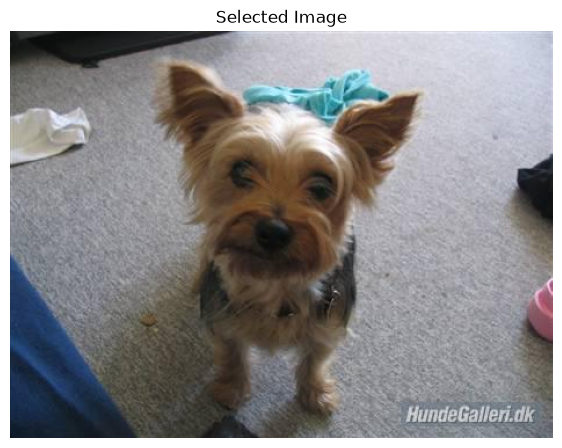

In [7]:
# ============================================================
# DISPLAY SELECTED IMAGE
# ============================================================

if image_path:

    original_image = Image.open(
        image_path
    ).convert("RGB")

    plt.figure(figsize=(7, 7))
    plt.imshow(original_image)
    plt.axis("off")
    plt.title("Selected Image")
    plt.show()

else:
    print("Please select an image first.")

In [8]:
# ============================================================
# IMAGE PREPROCESSING
# ============================================================

IMG_SIZE = 224

if image_path:

    image = original_image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    image_array = np.array(
        image,
        dtype=np.float32
    )

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    print("Image prepared successfully!")
    print("Image shape:", image_array.shape)
    print("Data type:", image_array.dtype)

Image prepared successfully!
Image shape: (1, 224, 224, 3)
Data type: float32


In [9]:
# ============================================================
# STAGE 1: DOG VS NON-DOG DETECTION
# ============================================================

if image_path:

    detector_predictions = dog_detector.predict(
        image_array,
        verbose=0
    )[0]

    detector_index = np.argmax(
        detector_predictions
    )

    detected_class = detector_classes[
        detector_index
    ]

    detector_confidence = (
        detector_predictions[
            detector_index
        ] * 100
    )

    print("=" * 50)
    print("DOG VS NON-DOG DETECTION")
    print("=" * 50)

    print("\nDetection:")
    print(detected_class)

    print(
        f"Confidence: "
        f"{detector_confidence:.2f}%"
    )

    print("\nProbabilities:")

    for index, class_name in enumerate(
        detector_classes
    ):

        probability = (
            detector_predictions[index] * 100
        )

        print(
            f"{class_name:10s}: "
            f"{probability:.2f}%"
        )

DOG VS NON-DOG DETECTION

Detection:
dog
Confidence: 93.41%

Probabilities:
dog       : 93.41%
non_dog   : 6.59%


In [10]:
# ============================================================
# STAGE 2: DOG BREED CLASSIFICATION
# ============================================================

if image_path:

    if detected_class != "dog":

        print("\n" + "=" * 50)
        print("RESULT")
        print("=" * 50)

        print("\n❌ NON-DOG IMAGE")
        print(
            f"Confidence: "
            f"{detector_confidence:.2f}%"
        )

        print(
            "\nDog breed classification "
            "was skipped."
        )

    else:

        breed_predictions = dog_breed_model.predict(
            image_array,
            verbose=0
        )[0]

        top_indices = np.argsort(
            breed_predictions
        )[::-1][:3]

        print("\n" + "=" * 50)
        print("TOP 3 DOG BREED PREDICTIONS")
        print("=" * 50)

        for rank, index in enumerate(
            top_indices,
            start=1
        ):

            breed = dog_breed_classes[index]

            confidence = (
                breed_predictions[index] * 100
            )

            print(
                f"{rank}. "
                f"{breed.replace('_', ' ')} "
                f"- {confidence:.2f}%"
            )


TOP 3 DOG BREED PREDICTIONS
1. Yorkshire terrier - 90.78%
2. shitzu - 1.91%
3. German shepherd - 1.81%


In [11]:
# ============================================================
# FINAL PAWCARE DOG AI RESULT
# ============================================================

if image_path:

    print("\n")
    print("=" * 60)
    print("🐶 PAWCARE DOG AI RESULT")
    print("=" * 60)

    if detected_class != "dog":

        print("\nAnimal Detection : NON-DOG")
        print(
            f"Confidence       : "
            f"{detector_confidence:.2f}%"
        )

        print(
            "\nDog breed prediction "
            "was not performed."
        )

    else:

        best_index = top_indices[0]

        best_breed = dog_breed_classes[
            best_index
        ]

        best_confidence = (
            breed_predictions[
                best_index
            ] * 100
        )

        print("\nAnimal Detection : DOG")

        print(
            f"Dog Confidence   : "
            f"{detector_confidence:.2f}%"
        )

        print(
            f"Predicted Breed  : "
            f"{best_breed.replace('_', ' ')}"
        )

        print(
            f"Breed Confidence : "
            f"{best_confidence:.2f}%"
        )

        print("\nTop 3 Predictions:")

        for rank, index in enumerate(
            top_indices,
            start=1
        ):

            breed = dog_breed_classes[
                index
            ].replace("_", " ")

            confidence = (
                breed_predictions[
                    index
                ] * 100
            )

            print(
                f"{rank}. "
                f"{breed} - "
                f"{confidence:.2f}%"
            )

    print("=" * 60)



🐶 PAWCARE DOG AI RESULT

Animal Detection : DOG
Dog Confidence   : 93.41%
Predicted Breed  : Yorkshire terrier
Breed Confidence : 90.78%

Top 3 Predictions:
1. Yorkshire terrier - 90.78%
2. shitzu - 1.91%
3. German shepherd - 1.81%


c:\Users\saisa\OneDrive\Documents\PawCare\venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 128054 (\N{DOG FACE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


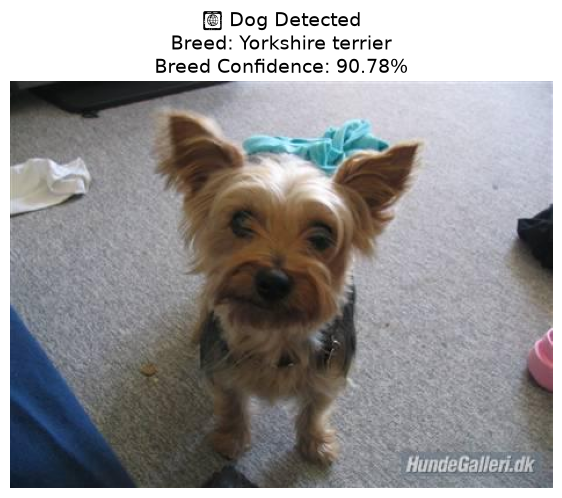

In [12]:
# ============================================================
# FINAL PREDICTION WITH IMAGE
# ============================================================

if image_path:

    plt.figure(figsize=(7, 7))
    plt.imshow(original_image)
    plt.axis("off")

    if detected_class == "dog":

        best_index = top_indices[0]

        best_breed = dog_breed_classes[
            best_index
        ].replace("_", " ")

        best_confidence = (
            breed_predictions[best_index] * 100
        )

        plt.title(
            f"🐶 Dog Detected\n"
            f"Breed: {best_breed}\n"
            f"Breed Confidence: {best_confidence:.2f}%",
            fontsize=14
        )

    else:

        plt.title(
            f"❌ Non-Dog Image\n"
            f"Confidence: {detector_confidence:.2f}%",
            fontsize=14
        )

    plt.show()

else:
    print("Please select an image first.")

In [13]:
# ============================================================
# ONE-CLICK DOG PREDICTION
# ============================================================

def pawcare_dog_predict():

    # --------------------------------------------------------
    # SELECT IMAGE
    # --------------------------------------------------------

    root = tk.Tk()
    root.withdraw()

    selected_path = filedialog.askopenfilename(
        title="Select an Image",
        filetypes=[
            (
                "Image Files",
                "*.jpg *.jpeg *.png *.bmp *.webp"
            )
        ]
    )

    root.destroy()

    if not selected_path:

        print("No image selected.")
        return

    # --------------------------------------------------------
    # LOAD IMAGE
    # --------------------------------------------------------

    selected_image = Image.open(
        selected_path
    ).convert("RGB")

    # --------------------------------------------------------
    # DISPLAY IMAGE
    # --------------------------------------------------------

    plt.figure(figsize=(7, 7))
    plt.imshow(selected_image)
    plt.axis("off")
    plt.title("Selected Image")
    plt.show()

    # --------------------------------------------------------
    # PREPROCESS IMAGE
    # --------------------------------------------------------

    image = selected_image.resize(
        (IMG_SIZE, IMG_SIZE)
    )

    image_array = np.array(
        image,
        dtype=np.float32
    )

    image_array = np.expand_dims(
        image_array,
        axis=0
    )

    # --------------------------------------------------------
    # STAGE 1
    # DOG VS NON-DOG DETECTION
    # --------------------------------------------------------

    detector_predictions = dog_detector.predict(
        image_array,
        verbose=0
    )[0]

    detector_index = np.argmax(
        detector_predictions
    )

    detected_class = detector_classes[
        detector_index
    ]

    detector_confidence = (
        detector_predictions[
            detector_index
        ] * 100
    )

    # --------------------------------------------------------
    # NON-DOG RESULT
    # --------------------------------------------------------

    if detected_class != "dog":

        print("\n" + "=" * 60)
        print("🐶 PAWCARE DOG AI RESULT")
        print("=" * 60)

        print("\n❌ NON-DOG IMAGE")

        print(
            f"Detector Confidence: "
            f"{detector_confidence:.2f}%"
        )

        print(
            "\nDog breed classification "
            "was skipped."
        )

        print("=" * 60)

        return

    # --------------------------------------------------------
    # STAGE 2
    # DOG BREED CLASSIFICATION
    # --------------------------------------------------------

    breed_predictions = dog_breed_model.predict(
        image_array,
        verbose=0
    )[0]

    top_indices = np.argsort(
        breed_predictions
    )[::-1][:3]

    # --------------------------------------------------------
    # BEST BREED
    # --------------------------------------------------------

    best_index = top_indices[0]

    best_breed = dog_breed_classes[
        best_index
    ]

    best_confidence = (
        breed_predictions[
            best_index
        ] * 100
    )

    # --------------------------------------------------------
    # PRINT FINAL RESULT
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print("🐶 PAWCARE DOG AI FINAL RESULT")
    print("=" * 60)

    print("\nAnimal Detection : DOG")

    print(
        f"Dog Confidence   : "
        f"{detector_confidence:.2f}%"
    )

    print(
        f"Predicted Breed  : "
        f"{best_breed.replace('_', ' ')}"
    )

    print(
        f"Breed Confidence : "
        f"{best_confidence:.2f}%"
    )

    print("\nTop 3 Predictions:")

    for rank, index in enumerate(
        top_indices,
        start=1
    ):

        breed = dog_breed_classes[
            index
        ].replace("_", " ")

        confidence = (
            breed_predictions[
                index
            ] * 100
        )

        print(
            f"{rank}. "
            f"{breed} - "
            f"{confidence:.2f}%"
        )

    print("=" * 60)

    # --------------------------------------------------------
    # DISPLAY IMAGE + FINAL PREDICTION
    # --------------------------------------------------------

    plt.figure(figsize=(8, 8))
    plt.imshow(selected_image)
    plt.axis("off")

    result_text = (
        f"🐶 Dog Detected\n\n"
        f"Breed: {best_breed.replace('_', ' ')}\n"
        f"Breed Confidence: {best_confidence:.2f}%"
    )

    plt.title(
        result_text,
        fontsize=14
    )

    plt.show()

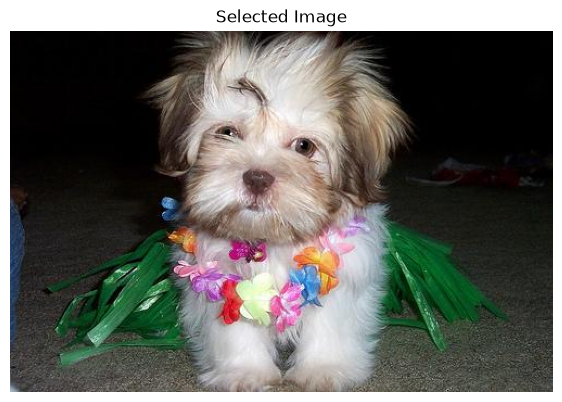


🐶 PAWCARE DOG AI FINAL RESULT

Animal Detection : DOG
Dog Confidence   : 93.61%
Predicted Breed  : shitzu
Breed Confidence : 77.09%

Top 3 Predictions:
1. shitzu - 77.09%
2. Yorkshire terrier - 18.29%
3. pug - 1.23%


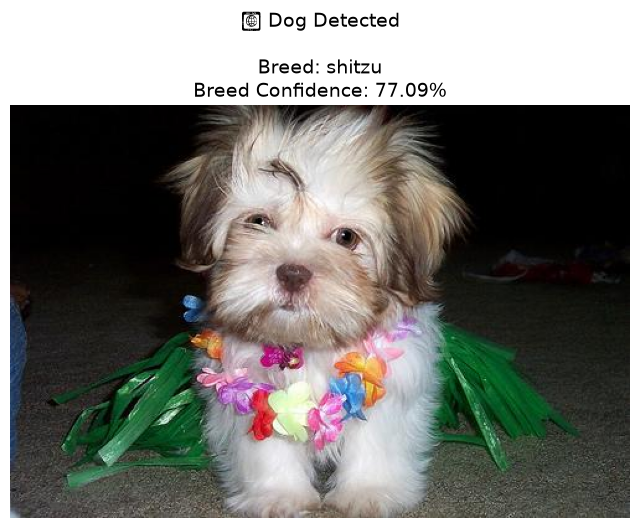

In [14]:
# ============================================================
# ONE-CLICK PREDICTION
# ============================================================

pawcare_dog_predict()

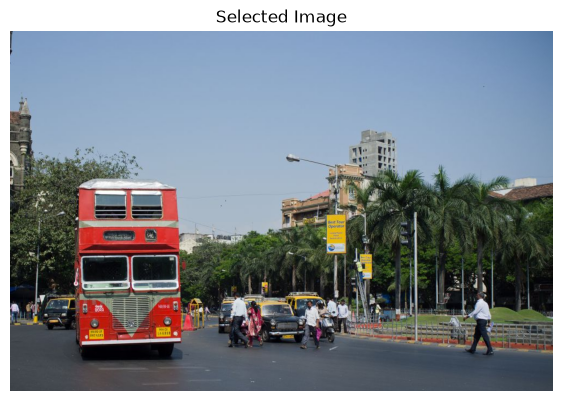


🐶 PAWCARE DOG AI RESULT

❌ NON-DOG IMAGE
Detector Confidence: 73.90%

Dog breed classification was skipped.


In [15]:
pawcare_dog_predict()